# 04 - Rolling hydrograph and worst-catchment checks

In [13]:
import sys
from pathlib import Path
FUNCTIONS_PATH = Path("/home/mokr/Reservoir_Modelling/ML_Functions/")
if str(FUNCTIONS_PATH) not in sys.path:
    sys.path.append(str(FUNCTIONS_PATH))

import os, pickle, shelve, gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D

from ML_Plots import plot_hydrograph_grid
from analysis_config import MODEL_NAME_MAP, MODEL_COLORS, SHELVE_RESULTS_PATH, ANALYSIS_CACHE_PATH

with open(ANALYSIS_CACHE_PATH, "rb") as f:
    avg_metrics_by_results = pickle.load(f)["avg_metrics_by_results"]

with shelve.open(SHELVE_RESULTS_PATH, flag="r") as db:
    no_flow_reservoir_lagged = dict(db.get("no_flow_reservoir", {}))
gc.collect()

test_res_tensor_metadata = torch.load("/perm/mokr/CamelsGB_V2/test_res_tensor_metadata.pt")

In [14]:
def get_basin_name(basin_idx, csv_base_path="/perm/mokr/Scaled_CamelsGB_V2"):
    # Split by underscore and take the first part as location
    csv_filename = f"normalised_static_data.csv"
    csv_path = os.path.join(csv_base_path, csv_filename)
    df = pd.read_csv(csv_path, engine="python")
    gauge_name = df[df["gauge_id"] == basin_idx]["gauge_name"].values[0]

    return gauge_name

## Worst-scoring reservoir gauges

In [15]:


models_dict = avg_metrics_by_results['no_flow_reservoir']

# Create a new DataFrame where each column is a model's 'NSE'
nse_df = pd.DataFrame({
    model_name: df['NSE'] 
    for model_name, df in models_dict.items()
})
nse_df = nse_df.sort_values(by='Reservoir_Embedded_LSTM')

lowest_score_indices = nse_df.idxmin()
print(lowest_score_indices)
nse_df


# Worst no_flow and flow reservoir catchment is 54003, for NonReservoir LSTM with flow data it is 8005. 54003 and 67001 are the only two with negative scores in the reservoir models
# Worst no_flow and flow nonreservoir catchment is 54020 and 54017, not really a problem though for any model but Reservoir model
## Vyrnwy at Vyrnwy Reservoir (54003), Dee at Bala (67001), both are in Wales and < 4.8km2 (lake size, not upstream area)
# Vyrnwy very multi use, bird protection, sailing, energy, etc, 100% reservoir contributing area
# Bala has 3 upstream reservoirs, 80% reservoir contributing area


# 8005, 54080, 68003, 65004 Have the Non Reservoir Model perform very Badly, and Reservoir model performin a lot better

Reservoir_Embedded_LSTM       54003
NonReservoir_Embedded_LSTM    54003
Full_Embedded_LSTM            54003
Hydra_Main                    54003
Hydra_ResHead                 54003
Hydra_NonResHead              54003
dtype: object


,Reservoir_Embedded_LSTM,NonReservoir_Embedded_LSTM,Full_Embedded_LSTM,Hydra_Main,Hydra_ResHead,Hydra_NonResHead
gauge_id,,,,,,
54003,-4.408923,-15.720950,-7.072582,-4.755613,-5.852197,-4.602663
67001,-0.186381,-0.917944,-0.192842,-0.151612,-0.101280,-0.429710
67033,0.380544,0.209198,0.380574,0.145867,0.090917,0.230434
41005,0.479756,0.315349,0.498830,0.530367,0.525697,0.494549
54001,0.490740,0.440651,0.536203,0.541132,0.538184,0.515165
54057,0.517063,0.334193,0.511601,0.541079,0.547096,0.540322
8005,0.536346,-2.676347,-0.075102,-0.292987,-0.361506,-0.435998
54032,0.542509,0.469658,0.559629,0.613069,0.606182,0.579229
54095,0.558510,0.559954,0.594072,0.585075,0.580520,0.546979


In [16]:
for gauge in avg_metrics_by_results['no_flow_reservoir']['Reservoir_Embedded_LSTM'].index.values:
    
    print(gauge, get_basin_name(int(gauge), csv_base_path="/perm/mokr/Scaled_CamelsGB_V2"))

16001 Earn at Kinkell Bridge
16004 Earn at Forteviot Bridge
2001 Helmsdale at Kilphedir
41005 Ouse at Gold Bridge
54001 Severn at Bewdley
54003 Vyrnwy at Vyrnwy Reservoir
54005 Severn at Montford
54028 Vyrnwy at Llanymynech
54032 Severn at Saxons Lode
54057 Severn at Haw Bridge
54080 Severn at Dolwen
54095 Severn at Buildwas
65004 Gwyrfai at Bontnewydd
65006 Seiont at Peblic Mill
67001 Dee at Bala
67006 Alwen at Druid
67015 Dee at Manley Hall
67033 Dee at Chester Suspension Bridge
68003 Dane at Rudheath
8005 Spey at Boat of Garten
8006 Spey at Boat o Brig
83009 Garnock at Kilwinning


## The catchment Reservoir_LSTM Performs Super badly at

-  https://nrfa.ceh.ac.uk/data/station/info/40010
-  40010 - Eden at Penshurst / Vexour Bridge
-  Largest on line flood storage reservoir of its kind in the UK.
-  Predominantly Impervious
-  Combined flow series from two separate stations Penshurst (low flows) and Vexour Bridge (high flows)
-  224 km2
-  Responsive flow regime in a small baseflow

## Hydrographs
`plot_hydrograph_grid` now lives in `ML_Plots` and replaces the old single-gauge function. It uses plain NSE; the old notebook redefined `calculate_nse` with a `+1e-1` term, so NSE values from the old hydrograph legends differ slightly (pass `nse_fn=` to reproduce them). Top row: one hydrograph per gauge. Bottom row: zoom on `zoom_days` days. Reservoir and natural gauges come from different results/metadata, so each panel carries its own.

Saved /home/mokr/Reservoir_Modelling/figures/hydrographs_2004.png


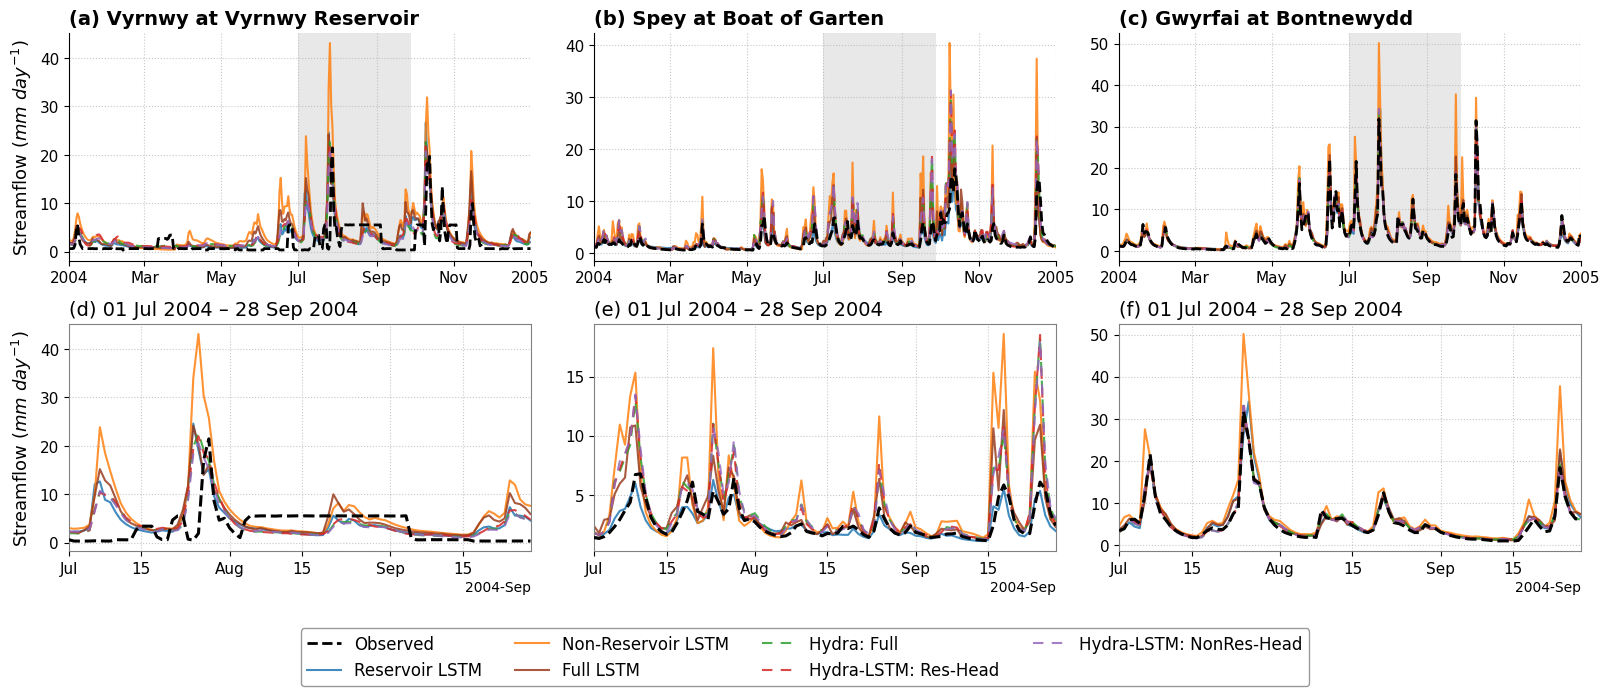

model            Full LSTM  Hydra-LSTM: NonRes-Head  Hydra-LSTM: Res-Head  \
gauge_id window                                                             
54003    full    -0.333688                 0.146165              0.027206   
         zoom    -1.406364                -0.623668             -0.822177   
65004    full     0.957021                 0.981878              0.986291   
         zoom     0.957385                 0.980113              0.984212   
8005     full     0.460530                 0.150972              0.164157   
         zoom    -0.712755                -1.806129             -1.766320   

model            Hydra: Full  Non-Reservoir LSTM  Reservoir LSTM  
gauge_id window                                                   
54003    full       0.081523           -1.764207       -0.037357  
         zoom      -0.779684           -4.292841       -0.946600  
65004    full       0.985485            0.686558        0.928008  
         zoom       0.983696            0.418144        0.899752  
8005     full       0.205971           -1.235135        0.786788  
         zoom      -1.702934           -5.255197        0.748216

In [23]:
# Metadata for the natural gauges (needed if any panel is a non-reservoir gauge)
test_non_res_tensor_metadata = torch.load("/perm/mokr/CamelsGB_V2/test_non_res_tensor_metadata.pt")
with shelve.open(SHELVE_RESULTS_PATH, flag="r") as db:
    no_flow_nonreservoir_lagged = dict(db.get("no_flow_nonreservoir", {}))

res = dict(models=no_flow_reservoir_lagged,    gauge_ids=test_res_tensor_metadata["gauge_id"],     dates=test_res_tensor_metadata["init_date"])
nat = dict(models=no_flow_nonreservoir_lagged, gauge_ids=test_non_res_tensor_metadata["gauge_id"], dates=test_non_res_tensor_metadata["init_date"])

panels = [
    {**res, "gauge_id": "54003", "name": "Vyrnwy at Vyrnwy Reservoir"},
    {**res, "gauge_id": "8005",  "name": "Spey at Boat of Garten"},
    {**res, "gauge_id": "65004", "name": "Gwyrfai at Bontnewydd"},   # replace with a real natural gauge id and name
]

fig, nse_table = plot_hydrograph_grid(
    panels,
    model_names=list(MODEL_NAME_MAP.values()),
    model_colors=MODEL_COLORS,
    start_date="2004-01-01", end_date="2005-01-01",
    zoom_start="2004-07-01", zoom_days=90,        # or zoom_start={"54003": "2004-07-01", "8005": "2004-09-01", ...}
    save_path="/home/mokr/Reservoir_Modelling/figures/hydrographs_2004.png",
    dpi=300,
)
nse_table.pivot_table(index=["gauge_id", "window"], columns="model", values="NSE")

### Notes from the old plotting cell
Gauge 54003 is Vyrnwy at Vyrnwy Reservoir (the old call labelled it 'Spey at Boat of Garten', which is 8005).

In [ ]:
## Define your lists
# names_list = ["Hydra Reservoir Head"]
# colors_list = ["#1F4E79", "#C0392B", "#1E6B3C", "#D35400", "#6C3483"]
# 8005, 54080, 68003, 65004 Have the Non Reservoir Model perform very Badly, and Reservoir model performin a lot better
# For 8005, 68003, 65004 that gain comes solely from dampening
# 54003 Vyrnwy at Vyrnwy Reservoir
# 65004 Gwyrfai at Bontnewydd
# 8005 Spey at Boat of Garten: 102, 33 for full year, 
# 8005 is probably the best to show, its still dampening but it's a serious dampening, 34 is 2005 and works, shows that the Hydra models are oaky too,  14 is good but only the reservoir model is good
# I should report the variance in this too, to make the point of dampening, 282 for 92 day hydrograph
# 54003 is Vyrnwy at Vyrnwy Reservoir (41 to get to Jan 1, 24 years, 222 for 1st July), 65004 Gwyrfai at Bontnewydd (312 to get to Jan1. 21 years from start, 142 for 1st July)
# Call the function